In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import Normalizer

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import Dataset


In [14]:
pip install torch torchvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 2.2 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [15]:
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

100%|██████████| 9.91M/9.91M [00:14<00:00, 669kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 86.5kB/s]
100%|██████████| 1.65M/1.65M [00:02<00:00, 775kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.98MB/s]


In [16]:
X = train_dataset
y = test_dataset

In [17]:
X.sample(10).iloc[:,200:]


AttributeError: 'MNIST' object has no attribute 'sample'

AttributeError: 'MNIST' object has no attribute 'iloc'

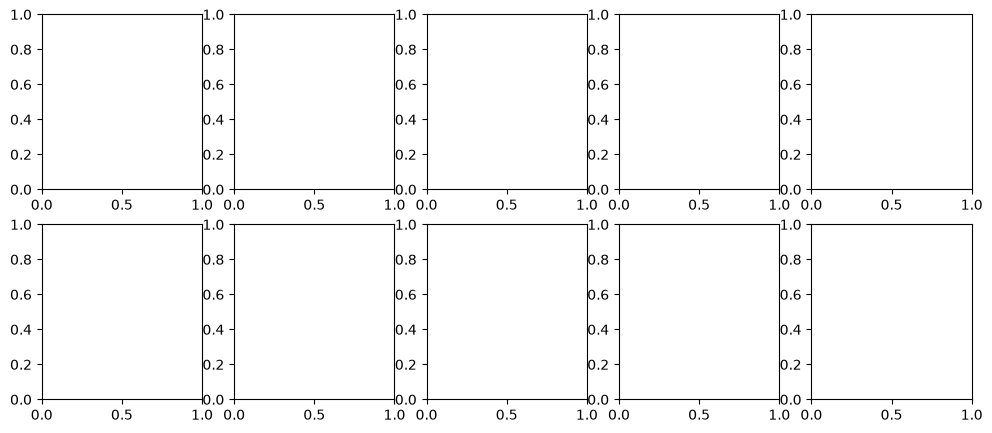

In [ ]:
fig,axes = plt.subplots(2,5, figsize = (12,5))
axes = axes.flatten()
idx = np.random.randint(0,60000,size = 10)
for i in range(10):
    axes[i].imshow(X.iloc[idx[i],:].values.reshape(28,28), cmap='gray')
    axes[i].axis('off')  #hide the axes ticks 
    axes[i].set_title(str(int(Y[idx[i]])), color = 'black',fontsize = 25)
plt.show()


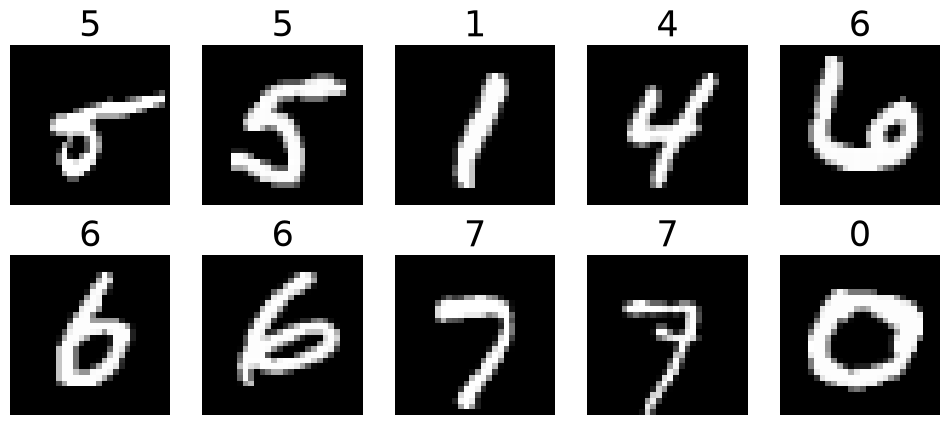

In [25]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.flatten()
idx = np.random.randint(0, len(X), size=10)

for i in range(10):
    image, label = X[idx[i]]          # image is a tensor of shape (1, 28, 28)
    axes[i].imshow(image.squeeze(), cmap='gray')
    axes[i].axis('off')
    axes[i].set_title(str(label), color='black', fontsize=25)

plt.show()

##### Dataset and DataLoader class

##### 1. Basic idea behind the dataset and dataloader class is to be decoupled from our model training code for better readability and modularity. 
#### 2. PyTorch provides two data primitives : torch.utils.data.loader and torch.utils.data.dataset that allow you to use pre-loaded datasets as well your own data.
#### 3. Dataset class stores the samples and their corresponding lables, and dataloader class wraps an iterable arount the dataset to enable easy access to the samples 

#### Dataset class 

##### A custom datasets must implement three fiunctions __init__, __len__, and __getitem__.


1. The init function is run once when initialising the dataset object. We initialize the directory containing the images, the annotations file, and both transforms
2. The len function returns the number of samples in the dataset. 
3. The getitem function loads and returns a sample from the dataset at the given idx. Based on the index, it identifies the sample and label and reurn it as a tuple. 


In [29]:
class CustomDataset(Dataset):
    def __init__(self, features, label):
        self.features = features
        self.label = label

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return self.features[idx], self.label[idx]